# 04 — Análise Exploratória e Hipóteses (Fase 3)

Explora o dataset de modelagem montado por `src/preprocessing/dataset.py` a
partir da camada Gold da Fase 2 — 1 linha por aluno de 2024 com prova
válida, 16 features disponíveis **antes** da prova (ver
`docs/decisoes_analiticas.md`, D1) e o alvo `alfabetizado`.

O enunciado pede que a EDA "apoie diretamente as decisões de modelagem e a
construção das hipóteses". Este notebook termina com 5 hipóteses explícitas,
testadas no notebook 05.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

from src.preprocessing.dataset import (FEATURES_CONTAGEM, FEATURES_NUMERICAS, TODAS_FEATURES,
                                       montar_dataset_modelagem)

df = montar_dataset_modelagem()
df[TODAS_FEATURES + ["alfabetizado"]].head()

[dataset] ano alvo 2024: 2,120,560 alunos listados -> 1,851,852 com prova válida
[dataset] 16 features | 5,517 municípios | taxa de alfabetizados 59.8%


[dataset] nulos (%): {'mun_n_alunos_ant': 23.1, 'taxa_alfabetizacao_ant': 1.9, 'nivel_alfabetizacao_ant': 4.7, 'participacao_ant': 4.7, 'meta_ano': 4.7, 'esforco_meta': 4.7, 'prof_media_ant': 23.1, 'prof_desvio_ant': 23.1, 'prof_p25_ant': 23.1}


,rede_label,escola_n_alunos,mun_n_alunos_ant,taxa_alfabetizacao_ant,nivel_alfabetizacao_ant,participacao_ant,meta_ano,esforco_meta,prof_media_ant,prof_desvio_ant,prof_p25_ant,idhm_educacao,idhm_longevidade,idhm_renda,capital_uf,amazonia_legal,alfabetizado
0,Municipal,132.0,492.0,49.82,1.0,88.01,54.78,4.98,742.832423,43.218202,711.406211,0.479,0.751,0.650,0.0,1.0,True
1,Municipal,43.0,20171.0,74.16,4.0,93.87,74.95,0.95,774.750716,56.898876,741.006090,0.695,0.824,0.749,1.0,0.0,True
2,Municipal,76.0,103.0,43.73,1.0,92.23,49.55,5.85,731.132583,42.533306,704.915441,0.560,0.782,0.608,0.0,0.0,False
3,Municipal,29.0,524.0,48.67,1.0,83.59,53.80,5.10,737.260960,35.093642,720.264421,0.572,0.761,0.588,0.0,0.0,False
4,Municipal,264.0,1831.0,66.34,3.0,89.85,68.56,2.26,752.887483,39.497829,730.004719,0.608,0.822,0.682,0.0,0.0,True


## 1. Alvo e população

Alunos com prova válida: 1,851,852
Municípios: 5,517
Taxa de alfabetizados: 59.8%
Baseline trivial (sempre 'alfabetizado'): acurácia 59.8%


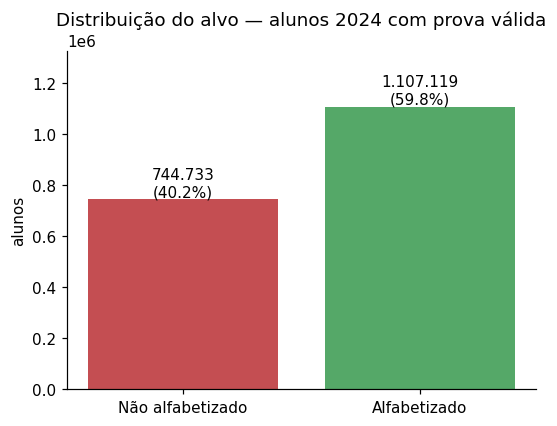

In [2]:
print(f"Alunos com prova válida: {len(df):,}")
print(f"Municípios: {df['id_municipio'].nunique():,}")
print(f"Taxa de alfabetizados: {df['alfabetizado'].mean():.1%}")
print(f"Baseline trivial (sempre 'alfabetizado'): acurácia {df['alfabetizado'].mean():.1%}")
display(Image(filename=str(ROOT / "images" / "01_distribuicao_alvo.png")))

Alvo moderadamente desbalanceado (~60/40). Duas consequências para a
modelagem: (1) acurácia sozinha engana — o baseline trivial já acerta ~60%,
então a métrica de escolha é ROC-AUC e todo resultado é comparado com esse
baseline; (2) não é necessário reamostrar (SMOTE) nem reponderar classes —
o que também preserva a calibração das probabilidades, necessária para
agregá-las por município.

## 2. Valores ausentes — e por que não são só ruído

In [3]:
nulos = df[TODAS_FEATURES].isna().mean().mul(100).round(1)
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(nulos.to_string())

sem_micro = df["prof_media_ant"].isna()
print(f"\nTaxa de alfabetização — com microdados do ano anterior: {df.loc[~sem_micro, 'alfabetizado'].mean():.1%}"
      f" | sem: {df.loc[sem_micro, 'alfabetizado'].mean():.1%}")

mun_n_alunos_ant           23.1
prof_desvio_ant            23.1
prof_p25_ant               23.1
prof_media_ant             23.1
nivel_alfabetizacao_ant     4.7
participacao_ant            4.7
meta_ano                    4.7
esforco_meta                4.7
taxa_alfabetizacao_ant      1.9

Taxa de alfabetização — com microdados do ano anterior: 60.2% | sem: 58.5%


~23% dos alunos estão em municípios sem microdados no ano anterior. Se a
taxa de alfabetização difere entre os dois grupos, a **ausência carrega
informação** — imputar só a mediana a apagaria. Decisão: imputação por
mediana **com indicador de ausência** (`SimpleImputer(add_indicator=True)`),
dentro do pipeline.

## 3. Associação entre features numéricas e o alvo

esforco_meta              -0.203
amazonia_legal            -0.050
prof_desvio_ant           -0.029
capital_uf                -0.026
escola_n_alunos           -0.011
mun_n_alunos_ant          -0.003
idhm_renda                 0.013
idhm_longevidade           0.035
idhm_educacao              0.039
participacao_ant           0.140
nivel_alfabetizacao_ant    0.220
meta_ano                   0.225
taxa_alfabetizacao_ant     0.240
prof_p25_ant               0.256
prof_media_ant             0.267


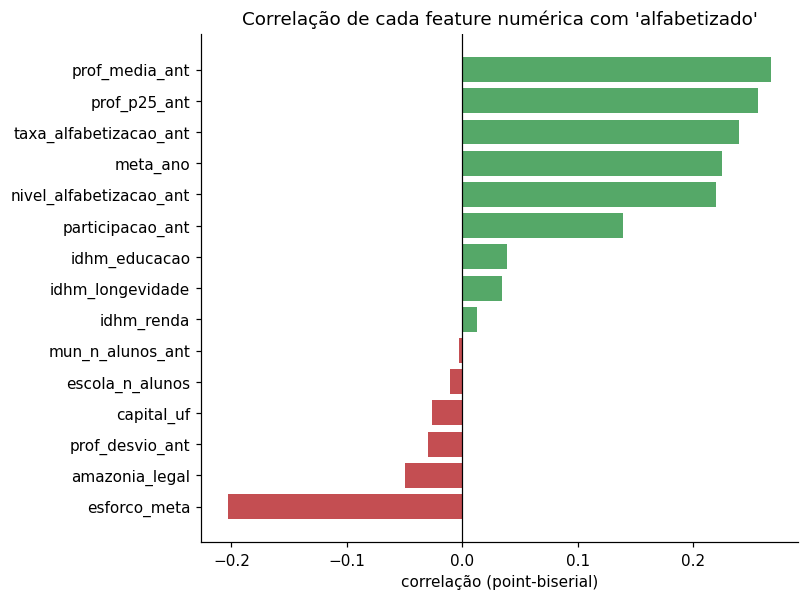

In [4]:
corr = (df[FEATURES_NUMERICAS + FEATURES_CONTAGEM + ["alfabetizado"]].astype(float)
        .corr()["alfabetizado"].drop("alfabetizado").sort_values())
print(corr.round(3).to_string())
display(Image(filename=str(ROOT / "images" / "03_correlacao_com_alvo.png")))

Leitura: as variáveis de **desempenho educacional do município no ano
anterior** (proficiência média, P25, taxa de alfabetização, nível, meta)
têm as maiores correlações positivas. O **esforço para atingir a meta** é a
mais negativa. Os componentes do **IDHM** — indicador socioeconômico amplo —
aparecem com correlações bem menores. Correlação univariada não controla
pelas outras variáveis; o modelo e a interpretabilidade (notebook 05) dizem
se isso se mantém em conjunto.

## 4. Transformação: contagens com cauda longa

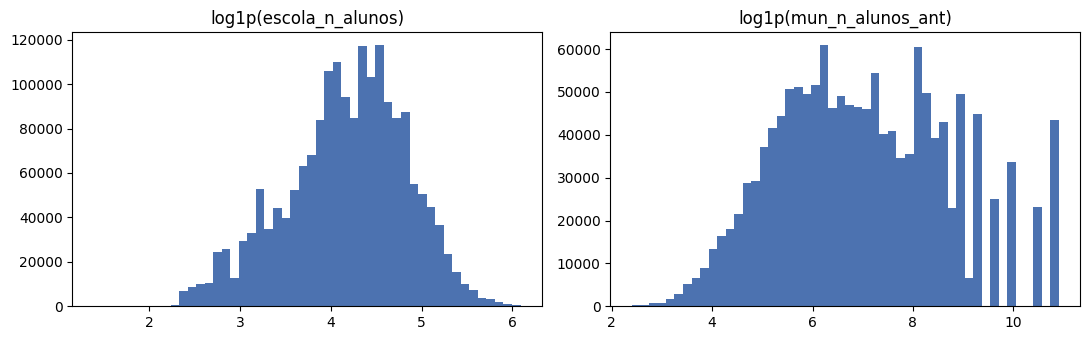

       escola_n_alunos  mun_n_alunos_ant
count        1851852.0         1423777.0
mean              78.0            4837.0
std               51.0           10494.0
min                3.0              10.0
25%               42.0             305.0
50%               68.0            1006.0
75%              103.0            3910.0
max              441.0           54533.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, FEATURES_CONTAGEM):
    ax.hist(np.log1p(df[col].dropna()), bins=50, color="#4C72B0")
    ax.set_title(f"log1p({col})")
plt.tight_layout(); plt.show()
print(df[FEATURES_CONTAGEM].describe().round(0).to_string())

Porte de escola e de município variam em ordens de grandeza (ver mínimo e
máximo na tabela acima) — `log1p` dentro do pipeline estabiliza a escala
para o modelo linear.

## 5. Diferenças territoriais

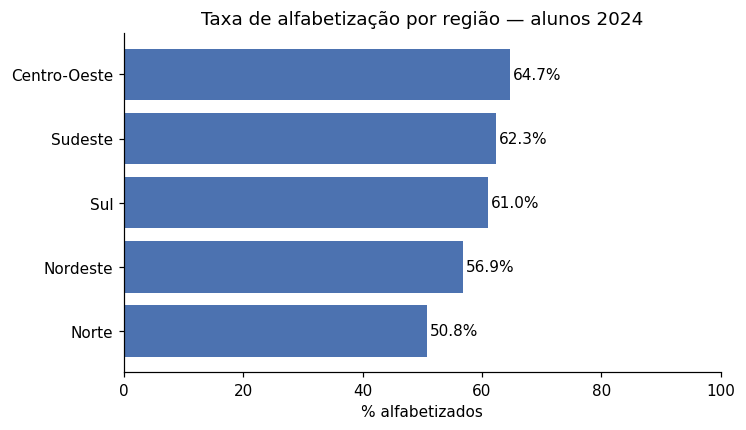

5 menores: {'BA': 36.0, 'SE': 38.6, 'RN': 40.0, 'RS': 45.8, 'AP': 47.3}
5 maiores: {'PR': 70.8, 'ES': 72.1, 'MG': 72.6, 'GO': 73.0, 'CE': 85.3}


In [6]:
display(Image(filename=str(ROOT / "images" / "02_taxa_por_regiao.png")))
taxa_uf = df.groupby("sigla_uf")["alfabetizado"].mean().sort_values()
print("5 menores:", (taxa_uf.head() * 100).round(1).to_dict())
print("5 maiores:", (taxa_uf.tail() * 100).round(1).to_dict())

Há diferença regional grande. Mas UF e região **não** entram como
feature: com um único ano de treino, o coeficiente de cada estado aprende o
choque daquele ano (D8 em `docs/decisoes_analiticas.md`) — o modelo tem que
explicar o território pelo **desempenho defasado** e pelo IDHM, que valem
para o ano seguinte.

## 6. Hipóteses analíticas (testadas no notebook 05)

- **H1** — O desempenho educacional do município no ano anterior é o fator
  mais associado ao resultado individual do aluno.
- **H2** — Indicadores socioeconômicos amplos (IDHM) pesam menos que o
  histórico educacional do município.
- **H3** — Quanto maior o esforço necessário para bater a meta do ano, menor
  a chance de o aluno estar alfabetizado.
- **H4** — O modelo é mais útil para **priorizar** (municípios e grupos de
  alunos) do que para prever com certeza um aluno específico — porque não há
  nenhuma informação individual do aluno nos dados.
- **H5** — Existem municípios com alfabetização alta apesar de contexto
  socioeconômico desfavorável — ou seja, o resultado não é determinado pelo
  território.